<a href="https://colab.research.google.com/github/tremwli/Python_programming/blob/main/%EB%B0%95%ED%95%98%EB%8A%98_14%EC%B0%A8%EC%8B%9C_%ED%95%99%EC%83%9D%EC%9A%A9_%EB%94%A5%EB%9F%AC%EB%8B%9D_CNN%EC%98%B7%EC%82%AC%EC%A7%84.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 14차시 합성곱 신경망(CNN)으로 옷 맞히기
지난 시간에는 손글씨 숫자를 한 줄로 펼쳐서(`Flatten`) 맞혔습니다. 오늘은 **그림의 모양을 보면서** 옷 사진을 읽는 모델을 만듭니다. 티셔츠, 바지, 운동화... AI가 몇 가지나 구별할까요?

**오늘 새로 배우는 것 4가지**
1. **필터**: 이미지 위를 작은 창(3×3)이 훑으며 선·모서리 같은 모양을 찾는 도구
2. **합성곱 층(`Conv2D`)**: 필터를 여러 개 쓰는 층
3. **풀링(`MaxPooling2D`)**: 이미지 크기를 절반으로 줄이는 층
4. **채널**: 이미지 한 장의 모양 `(높이, 너비, 채널)`. 흑백은 채널이 1

위에서부터 순서대로 한 셀씩 실행하세요.

# 1. 데이터 준비

In [2]:
!pip install tensorflow.keras

In [3]:
# 라이브러리 불러오기
import numpy as np
import matplotlib.pyplot as plt
import os
import cv2
from skimage import data
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense

In [4]:
# 옷 사진 데이터 불러오기 + 0~1로 만들기
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()
X_train = X_train / 255
X_test = X_test / 255



# 숫자 0~9에 해당하는 옷 이름
names = ['T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat',
         'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


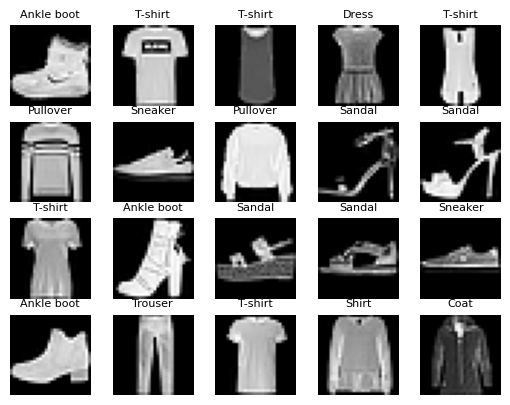

In [5]:
# 옷 사진 20장 보기
for i in range(20):
    plt.subplot(4,  5, i + 1) # 4행, 5열, 몇 번째 칸에 그릴지
    plt.imshow(X_train[i], cmap='gray')
    plt.title(names[y_train[i]], fontsize=8)
    plt.axis('off')
plt.show()

## 1-1. 필터 체험: 필터마다 찾는 모양이 다르다
`Conv2D`가 하는 일을 눈으로 봅니다. **필터**는 3×3 숫자표이고, 사진 위를 훑으며 계산합니다. 같은 사진에 필터 3개를 써 봅니다. 코드는 실행만 하세요.

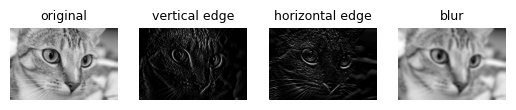

In [6]:
# 13차시의 고양이 사진 준비
if not os.path.exists('sample.png'):
    cv2.imwrite('sample.png', cv2.cvtColor(data.chelsea(), cv2.COLOR_RGB2BGR)) # imwrite(경로, 이미지) cv2.cvtColor(이미지, rgb를 bgr로 순서를 바꿔야됨 오픈 cv특)
img = cv2.imread('sample.png', cv2.IMREAD_GRAYSCALE) # cv2.(경로, 옵션(흑백으로 해주세요)) > 디스크의 이미지 파일을 읽어 숫자 배열로 가져옴

# 필터 3개
filter_v = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])       #  세로 경계를 찾는 필터 (엣지)
filter_h = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]])       #  가로 경계를 찾는 필터
filter_b = np.ones((10, 10)) / 100                              #  블러 만드는 필터

# 필터를 적용해서 비교
titles = ['original', 'vertical edge', 'horizontal edge', 'blur']
images = [img] + [cv2.filter2D(img, -1, f) for f in [filter_v, filter_h, filter_b]] # cv2.filter2D(img, -1, f) : img에 f를 적용, 이미지 담은 리스트 만들기
for i in range(4):
    plt.subplot(1, 4, i + 1) # 1행 4열 공간
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i], fontsize=9)
    plt.axis('off')
plt.show()

---
### 잠깐 멈추기
1. 세로 경계 필터와 가로 경계 필터는 각각 어떤 모양을 잘 찾았나요?
2. 흐리게 만드는 필터는 사진을 어떻게 바꾸었나요?

1. 세로 경계 필터는 고양이의 수염 옆선·눈 테두리처럼 세로 방향 선을, 가로 경계 필터는 눈 위아래 경계·턱선처럼 가로 방향 선을 밝게 찾아냈다. 필터의 숫자 배치(왼쪽 음수·오른쪽 양수 / 위 음수·아래 양수)에 따라 찾는 모양이 달라진다.
2. 블러 필터는 주변 10×10 칸의 평균을 내기 때문에 세부 모양(털, 경계)이 뭉개져 사진이 흐려졌다.
핵심: CNN 의 Conv2D 는 이런 필터의 숫자를
사람이 정하지 않고, 학습으로 스스로 찾는다. (필터 숫자 = 학습되는 가중치)

### 도전: 내 필터 만들어 보기
필터는 3×3 숫자표입니다. 아래 `my_filter`의 **숫자를 바꿔서** 다시 실행해 보세요. 어떤 모양이 잘 보이게 되는지 친구와 비교해 보세요.

- 처음 값은 **대각선(/ 방향)** 경계를 찾는 필터입니다.
- 숫자를 모두 `1`로 바꾸고 `/ 9`를 하면 흐리게 만드는 필터가 됩니다.
- 가운데를 `5`, 나머지를 `-1`로 하면 선명하게 만드는 필터가 됩니다.

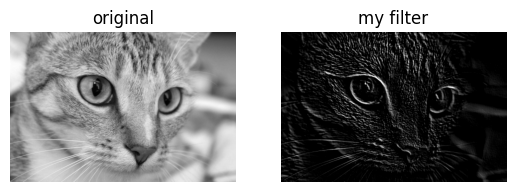

In [7]:
# 내 필터로 고양이 사진 훑기 (숫자를 바꿔서 여러 번 실행해 보세요)
my_filter = np.array([[ 0,  1,  2],
                      [-1,  0,  1],
                      [-2, -1,  0]])
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('original')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(cv2.filter2D(img, -1, my_filter), cmap='gray')
plt.title('my filter')
plt.axis('off')
plt.show()

## 1-2. 채널 칸 붙이기
`Conv2D`는 이미지가 `(높이, 너비, 채널)` 모양이길 원합니다. 흑백 사진은 채널이 **1**입니다.

### 직접 해보기
빈칸에 알맞은 숫자를 넣어 `(60000, 28, 28, 1)`이 되게 하세요.

**힌트**: 흑백의 채널 수는 얼마인가요?

In [1]:
# 이미지에 채널 칸 붙이기: (장수, 28, 28) -> (장수, 28, 28, 1)
X_train = X_train.reshape(-1, 28, 28, 1) # 맨 앞 -1 : 맨 앞에 안 넣은 숫자는 니가 알아서 넣어줘 > ㅇㅋ 알아서 장수 (60000) 넣어줄게
X_test = X_test.reshape(-1, 28, 28, 1)
print(X_train.shape)

NameError: name 'X_train' is not defined

목표 결과:
```
(60000, 28, 28, 1)
```

# 2. CNN 모델 만들기
순서는 **필터로 훑기(`Conv2D`) → 크기 줄이기(`MaxPooling2D`) → 펼치기(`Flatten`) → 숫자 맞히기(`Dense`)** 입니다.

### 직접 해보기
`Conv2D`(필터 32개, 3×3)와 `MaxPooling2D`(2×2) 층을 빈칸에 채우세요.

**힌트**: `Conv2D(필터 수, (3, 3), activation='relu')`, `MaxPooling2D((2, 2))`

In [8]:
# CNN 모델 만들기: 입력 → 훑기 → 줄이기 → 펼치기 → 출력
model = Sequential() # 층을 쌓아서 빈 신경망 틀 만들기
model.add(Input(shape=(28, 28, 1))) # 모델에 들어올 입력 데이터 모양. 높이 28, 너비 28, 채널 1짜리 하나씩 받겠다
model.add(Conv2D(32, (3, 3), activation='relu'))   # 3 * 3 크기의 필터 32개로 훑기
model.add(MaxPooling2D(2, 2))                    # 크기를 절반으로 줄이기
model.add(Flatten())
model.add(Dense(10, activation='softmax'))

In [9]:
# 층마다 출력 모양과 파라미터 수 확인
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        54,090 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 54,410 (212.54 KB)

 Trainable params: 54,410 (212.54 KB)

 Non-trainable params: 0 (0.00 B)

목표 결과 (표 모양은 달라도 **숫자**를 확인하세요):
```
conv2d (Conv2D)                 (None, 26, 26, 32)    320
max_pooling2d (MaxPooling2D)    (None, 13, 13, 32)    0
flatten (Flatten)               (None, 5408)          0
dense (Dense)                   (None, 10)            54,090
Total params: 54,410
```
---
### 잠깐 멈추기
1. `MaxPooling2D`를 지나자 가로·세로가 각각 몇 칸으로 줄었나요?
2. 13차시 모델의 파라미터는 101,770개였습니다. 오늘 CNN은 몇 개인가요? 어느 쪽이 더 작나요?
3. `Conv2D` 층의 파라미터는 320개입니다. 3×3 필터 32개이면 숫자가 몇 개일까요? (9 × 32 = 288, 나머지 32개는 필터마다 하나씩 더하는 값)

# 3. 학습시키기

In [10]:
# 학습 방법 정하기
model.compile(optimizer='Adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
''

### 직접 해보기
학습용 데이터를 **3번** 반복해서 학습시키세요. (CNN은 계산이 많아 조금 오래 걸립니다.)

**힌트**: `epochs=` 자리입니다.

In [11]:
# 학습용 데이터 전체를 3번 반복해서 학습
history = model.fit(X_train, y_train, epochs=3, validation_data=(X_test, y_test))

Epoch 1/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 22s 11ms/step - accuracy: 0.8470 - loss: 0.4410 - val_accuracy: 0.8749 - val_loss: 0.3535
Epoch 2/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.8904 - loss: 0.3143 - val_accuracy: 0.8898 - val_loss: 0.3152
Epoch 3/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 16s 9ms/step - accuracy: 0.9018 - loss: 0.2790 - val_accuracy: 0.8926 - val_loss: 0.3001


# 4. 학습 곡선

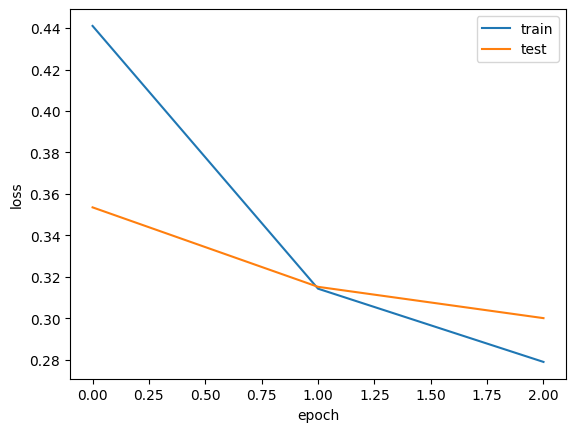

In [12]:
# loss 곡선
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='test')
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend()
plt.show()

### 직접 해보기
정확도 곡선의 테스트용 선이 그려지도록 빈칸을 채우세요.

**힌트**: 테스트용 정확도의 이름은 `val_`로 시작합니다.

KeyError: '____'

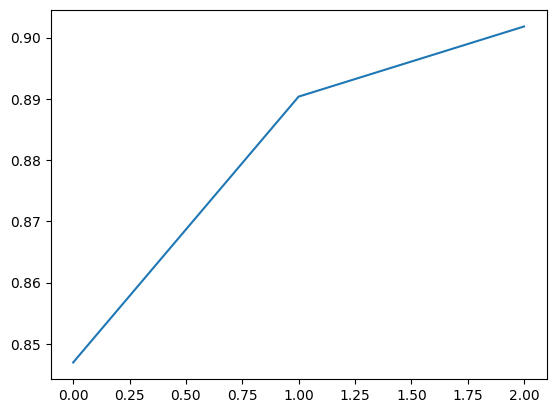

In [13]:
# accuracy 곡선: 학습용과 테스트용
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['____'], label='test')
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.legend()
plt.show()

# 5. 13차시 모델과 비교
13차시의 Flatten+Dense 모델을 같은 조건(3번 반복)으로 다시 학습시켜 비교합니다. 앞 두 셀은 주어진 코드입니다.

In [ ]:
# 13차시 모델(Flatten+Dense)을 같은 데이터로 다시 학습
dense_model = Sequential()
dense_model.add(___(shape=(28, 28, 1)))
dense_model.add(___())
dense_model.add(___(128, activation='relu'))
dense_model.add(___(10, activation='softmax'))
dense_model.___(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
dense_history = dense_model.___(X_train, y_train, epochs=3, validation_data=(X_test, y_test))

### 직접 해보기
두 모델의 마지막 epoch 테스트용 정확도를 비교하세요. 빈칸에 테스트용 정확도의 이름을 넣으세요.

In [ ]:
# 마지막 epoch의 테스트용 정확도 비교
print('CNN:', round(history.history['____'][-1], 4))
print('Dense:', round(dense_history.history['____'][-1], 4))
print('CNN 파라미터:', model.count_params())
print('Dense 파라미터:', dense_model.count_params())

# 6. AI가 옷을 맞힐 수 있을까?
테스트용 사진 10장에 대한 CNN의 답을 확인합니다. 코드는 실행만 하세요.

In [ ]:
# 테스트 사진 10장: 정답과 AI의 답
pred = model.predict(X_test[:10], verbose=0).argmax(axis=1)
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')
    plt.title(names[y_test[i]] + ' -> ' + names[pred[i]], fontsize=7)
    plt.axis('off')
plt.show()
print('맞힌 개수:', (pred == y_test[:10]).sum(), '/ 10')

## 6-2. AI가 틀린 옷 찾기
AI는 1만 장 중 몇 장을 틀렸을까요? 틀린 사진 9장을 봅니다. 코드는 실행만 하세요.

In [ ]:
# AI가 틀린 사진 9장 보기
pred_all = model.predict(X_test, verbose=0).argmax(axis=1)
wrong = np.where(pred_all != y_test)[0]
print('틀린 사진 수:', len(wrong), '/', len(y_test))
for k in range(min(9, len(wrong))):
    i = wrong[k]
    plt.subplot(3, 3, k + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')
    plt.title('answer ' + names[y_test[i]] + ' / AI ' + names[pred_all[i]], fontsize=7)
    plt.axis('off')
plt.show()

### 잠깐 멈추기
1. AI가 틀린 사진은 어떤 옷끼리 헷갈렸나요?
2. 이 사진들은 사람이 봐도 헷갈리나요?

## 6-3. AI에게 고양이를 보여주면?
이 AI는 옷 사진만 배웠습니다. 13차시의 고양이 사진을 28×28로 줄여 보여주면 뭐라고 답할까요? 코드는 실행만 하세요.

In [ ]:
# AI에게 고양이 사진 보여주기
filename = 'sample.png'   # 내 사진을 올렸다면 파일 이름으로 바꾸세요
photo = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)
photo = cv2.resize(photo, (28, 28)) / 255
# photo = 1 - photo   # 배경이 흰색인 사진이면 앞의 #를 지우세요 (옷 데이터는 배경이 검정)
prob = model.predict(photo.reshape(1, 28, 28, 1), verbose=0)[0]
print('AI의 답:', names[prob.argmax()], '| 확신:', round(prob.max() * 100), '%')
plt.imshow(photo, cmap='gray')
plt.axis('off')
plt.show()

### 잠깐 멈추기
1. AI가 고양이를 뭐라고 답했나요? 그 답이 맞나요?
2. 왜 이런 답이 나왔을까요?

---
## 오늘 정리
- **필터**가 이미지 위를 훑어 모양을 찾고, `Conv2D`는 필터 여러 개를 쓰는 층이다.
- `MaxPooling2D`는 이미지 크기를 절반으로 줄인다.
- 필터 숫자에 따라 찾는 모양(세로선, 가로선 등)이 다르고, `Conv2D`는 이 필터를 학습으로 정한다.
- 흑백 이미지는 `(높이, 너비, 1)` 모양이어야 `Conv2D`에 들어간다.
- CNN은 Dense 모델보다 파라미터가 적어도 이미지를 잘 맞힌다.
- AI는 **배운 것만 안다**. 옷만 배운 AI는 고양이도 옷으로 답한다.

다음 시간에는 **컬러 사진**으로 시험 형식 연습을 합니다.